In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize, MaxAbsScaler
from sklearn.metrics import average_precision_score, confusion_matrix, roc_auc_score, roc_curve, PrecisionRecallDisplay
import seaborn as sns
from global_land_mask import globe
import rasterio
import rasterio.features
import rasterio.warp
import h3

SEED = 0
LABEL_SMOOTHING = 0.0

In [1]:
SEED=0
res=4
Abs_per_presence=1

# Load training data
train = np.load('species/species_train.npz')

# Grid- every H3 cell on the globe
grid_cells = [c for r0 in h3.get_res0_cells() for c in h3.cell_to_children(r0, res)]
grid = np.array([h3.cell_to_latlng(c) for c in grid_cells]) # centers
cell_index = {c: i for i, c in enumerate(grid_cells)}
print('Grid cells-', len(grid))

df = pd.DataFrame({'lat': train['train_locs'][:, 0], 'lon': train['train_locs'][:, 1], 'species': train['train_ids'],})
print('Sightings-', len(df))

def near_land(lat, lon, step=.25): # .25 d- about 28km N-S
    near = np.zeros(len(lat), dtype=bool)
    for dlat in (-step, 0, step):
        for dlon in (-step, 0, step):
            clip_lat = np.clip(lat+dlat,-90,90)
            clip_long = np.clip(lon+dlon,-180,180)
            near |= globe.is_land(clip_lat, clip_long)
    return near

# Remove ocean sightings- about 25km from land
df = df[near_land(df['lat'].values, df['lon'].values)].copy()
print('Total after removing ocean sightings-', len(df))
land_cells = np.flatnonzero(near_land(grid[:, 0], grid[:, 1]))
print('Land cells-', len(land_cells))

# Bin- find the H3 cell each sighting falls in
df['cell'] = [cell_index[h3.latlng_to_cell(lat, lon, res)] for lat, lon in zip(df['lat'], df['lon'])]

# Presence only- one row per (cell, species)
presences = df.groupby(['cell', 'species']).size().reset_index(name='n_sightings') # Keep number of sightings
presences['present'] = 1
print('Presences after binning-', len(presences))

# Pseudo-absences- random grid cells (not same as presences but could be in the neighboring cell)
rng = np.random.default_rng(SEED)
absences = []
for species, group in presences.groupby('species'):
    candidates = np.setdiff1d(land_cells, group['cell']) # Pseudo-absences in cells where presences are not there
    picked = rng.choice(candidates, len(group)*Abs_per_presence, replace=False)
    absences.append(pd.DataFrame({'cell': picked, 'species': species, 'present': 0, 'n_sightings': 0}))

data = pd.concat([presences]+absences, ignore_index=True)
print('Pseudo-absences-', (data['present']==0).sum())

# Index for species 0-499
species_index = {taxon: i for i, taxon in enumerate(train['taxon_ids'])}
data['index'] = data['species'].map(species_index)

# Taxonomy class for species
taxonomy = pd.read_csv('species/species_taxonomy.csv')
species_class = dict(zip(taxonomy['taxon_id'], taxonomy['class']))
data['class'] = data['species'].map(species_class)

# Number for each class 
# {0: 'Amphibia', 1: 'Aves', 2: 'Crocodylia', 3: 'Mammalia', 4: 'Squamata', 5: 'Testudines'}
class_names = sorted(taxonomy['class'].unique()) 
class_index = {}
for i, c in enumerate(class_names):
    class_index[c] = i
data['class_id'] = data['class'].map(class_index)

# Features- normalise lat/lon to [-1,1], then sin/cos (SINR paper approach)
def encode(latlon):
    lat = latlon[:,0]/90
    lon = latlon[:,1]/180
    return np.column_stack([np.sin(np.pi*lon), np.cos(np.pi*lon), np.sin(np.pi*lat), np.cos(np.pi*lat)])

X_train = encode(grid[data['cell']])
y_train = data['present'].values
species_train = data['species'].values

# Save
np.savez('species/preprocessed_species.npz', id=data['index'].values, X_train=X_train, y_train=y_train, species_train=species_train, class_id=data['class_id'].values, n_sightings=data['n_sightings'].values, cell_train=data['cell'].values, grid_latlon=grid, grid_cells=np.array(grid_cells), res=res, taxon_ids=train['taxon_ids'])
print('X_train-', X_train.shape, ', y_train-', y_train.shape)

# Usage for models
preprocessed = np.load('species/preprocessed_species.npz')
cols = ['sin_lon', 'cos_lon', 'sin_lat', 'cos_lat']
train_df = pd.DataFrame(preprocessed['X_train'], columns=cols)
train_df['id'] = preprocessed['id']
train_df['class_id'] = preprocessed['class_id']
train_df['species'] = preprocessed['species_train']
train_df['present'] = preprocessed['y_train']
train_df['sightings'] = preprocessed['n_sightings']

X = preprocessed['X_train']
y = preprocessed['y_train']

print(train_df.head())


Grid cells- 288122
Sightings- 272037
Total after removing ocean sightings- 271239
Land cells- 89277
Presences after binning- 69497
Pseudo-absences- 69497
X_train- (138994, 4) , y_train- (138994,)
    sin_lon   cos_lon   sin_lat   cos_lat   id  class_id  species  present  \
0  0.517536  0.855661  0.632448 -0.774602  111         1   145300        1   
1  0.491174  0.871061  0.637845 -0.770165  111         1   145300        1   
2  0.474143  0.880448  0.636310 -0.771434  446         1    12707        1   
3  0.474143  0.880448  0.636310 -0.771434   60         1    12735        1   
4  0.474143  0.880448  0.636310 -0.771434   25         1    13851        1   

   sightings  
0          1  
1          1  
2          2  
3          1  
4          2  


In [3]:
# Load the climate grid
env_grid = np.load('bioclim_h3_res4.npz')['env_grid']

cols = ['sin_lon', 'cos_lon', 'sin_lat', 'cos_lat']

env_cols = ['Annual Mean Temperature',
            'Temperature Seasonality',
            'Max Temperature of Warmest Month',
            'Min Temperature of Coldest Month',
            'Annual Precipitation',
            'Precipitation Seasonality',
            'Precipitation of Driest Quarter',
            'Elevation']

# Load the preprocessed species data
preprocessed_species = np.load('species/preprocessed_species.npz')

# Make the train df from the preprocessed species data
species_df_bio = pd.DataFrame(preprocessed_species['X_train'], columns=cols)
species_df_bio['cell'] = preprocessed_species['cell_train']
species_df_bio['id'] = preprocessed_species['id']
species_df_bio['present'] = train_df['present']

# climate for each cell
species_df_bio[env_cols] = env_grid[species_df_bio['cell'].values]

# Drop cells with no climate data (ocean)
clean_species = species_df_bio[env_cols].notna().all(axis=1).values
species_df_bio = species_df_bio[clean_species]

X_species_bio = species_df_bio[cols].values

# Save
np.savez('preprocessed_species_bio.npz',
         id=preprocessed_species['id'][clean_species],
         X_train=X_species_bio,
         y_train=preprocessed_species['y_train'][clean_species],
         species_train=preprocessed_species['species_train'][clean_species],
         class_id=preprocessed_species['class_id'][clean_species],
         n_sightings=preprocessed_species['n_sightings'][clean_species],
         cell_train=preprocessed_species['cell_train'][clean_species],
         grid_latlon=preprocessed_species['grid_latlon'],
         grid_cells=preprocessed_species['grid_cells'],
         res=preprocessed_species['res'],
         taxon_ids=preprocessed_species['taxon_ids'],
         env_names=np.array(env_cols))
print('X_species_bio-', X_species_bio.shape, ', dropped-', (~clean_species).sum(), 'rows')

X_species_bio- (137968, 4) , dropped- 1026 rows


In [8]:
#Train validation split

#Stratify by species and present
stratify_crit = species_df_bio['id'].astype(str) + '_' + species_df_bio['present'].astype(str)

train_set, valid_set = train_test_split(species_df_bio, test_size=0.25, random_state=SEED, shuffle=True, stratify=stratify_crit)

In [12]:
rfc = RandomForestClassifier(criterion="entropy", random_state=SEED)
rfc = rfc.fit(train_set.drop("present",axis=1), train_set["present"])

In [14]:
valid_set.columns

Index(['sin_lon', 'cos_lon', 'sin_lat', 'cos_lat', 'cell', 'id', 'present',
       'Annual Mean Temperature', 'Temperature Seasonality',
       'Max Temperature of Warmest Month', 'Min Temperature of Coldest Month',
       'Annual Precipitation', 'Precipitation Seasonality',
       'Precipitation of Driest Quarter', 'Elevation'],
      dtype='str')

In [15]:
pred_pp = rfc.predict(valid_set.drop("present",axis=1))
acc_t_rfc = rfc.score(train_set.drop("present",axis=1), train_set["present"])
acc_rfc = rfc.score(valid_set.drop("present",axis=1), valid_set["present"])
pred_prob = rfc.predict_proba(valid_set.drop("present",axis=1))
print(f"{'='*10}\nTrain: {acc_t_rfc*100:.2f}%\nValidation: {acc_rfc*100:.2f}%")
#pred_4 = clf_4.predict(X_test)

Train: 99.99%
Validation: 85.45%


In [29]:
aps = {}
aus = {}

for sp, g in train_set.groupby("id"):
    prob_pred_sp = rfc.predict_proba(g.drop("present", axis=1))
    aps[sp] = average_precision_score(g["present"], prob_pred_sp[:, 1])
    aus[sp] = roc_auc_score(g["present"], prob_pred_sp[:, 1])

    fpr, tpr, _ = roc_curve(g["present"], prob_pred_sp[:, 1])

mAP = np.mean(list(aps.values()))
auc = np.mean(list(aus.values()))
mean_tpr = np.mean(tpr, axis=0)
#mean_tpr[0], mean_tpr[-1] = 0, 1

In [22]:
print(f"MAP: {mAP*100:.2f}")
print(f"mean AUC: {np.mean(auc):.3f}")

MAP: 100.00


<Axes: xlabel='feature', ylabel='importance'>

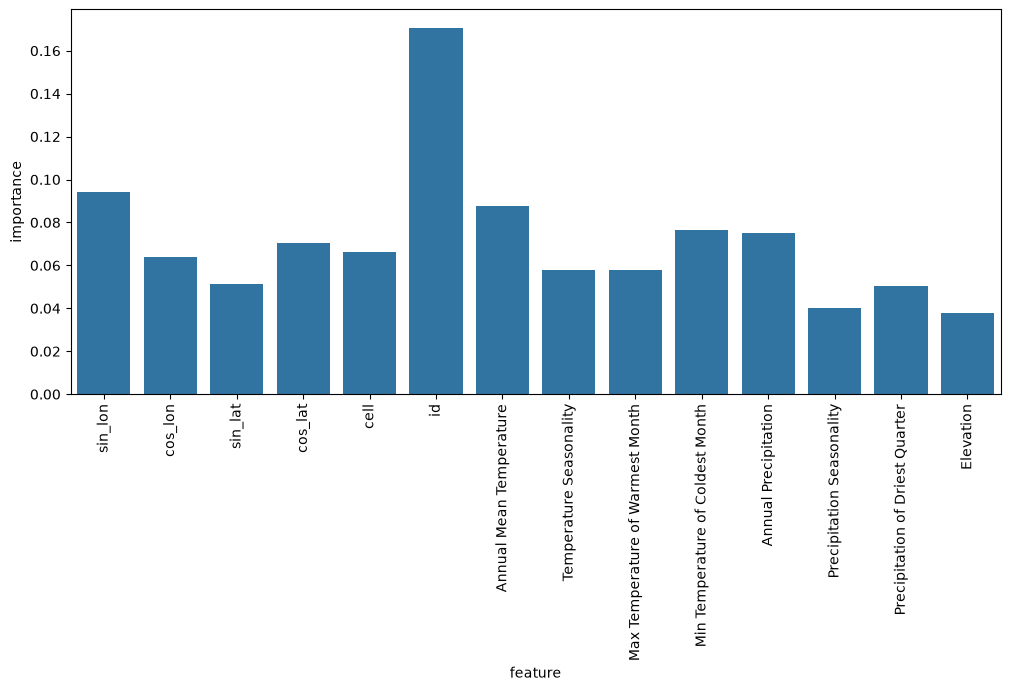

In [42]:
df_fi = pd.DataFrame(columns=["feature", "importance"])
df_fi["feature"] = train_set.drop("present",axis=1).columns
df_fi["importance"] = rfc.feature_importances_
plt.figure(figsize=(12,5))
plt.xticks(rotation=90)
sns.barplot(df_fi, x="feature", y="importance")

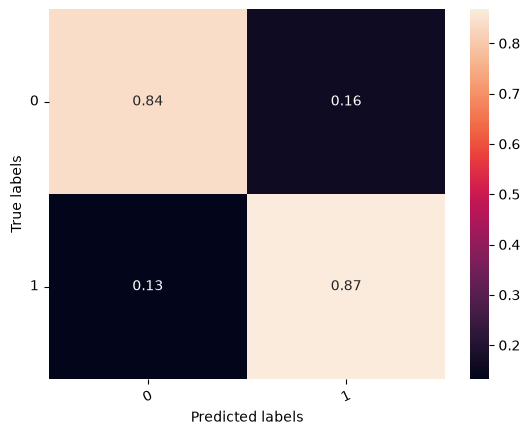

In [24]:
matrix = confusion_matrix(valid_set["present"], pred_pp)
matrix = matrix.astype('float') / matrix.sum(axis=1)[:, np.newaxis]
sns.heatmap(matrix, annot=True, fmt=".2f")
plt.xticks(rotation=25)
plt.yticks(rotation=0)
plt.xlabel("Predicted labels")
plt.ylabel("True labels")
plt.show()

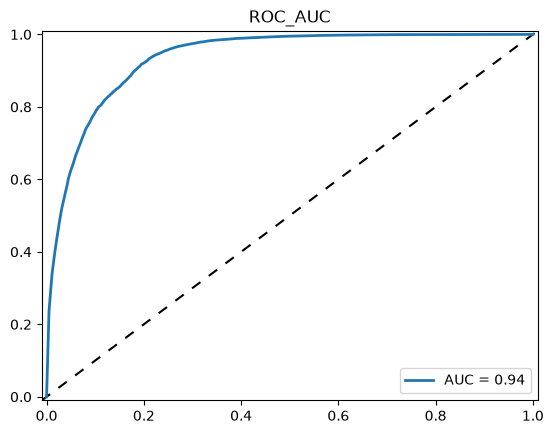

In [25]:
prob_pred_sp_all = rfc.predict_proba(valid_set.drop("present", axis=1))[:, 1]
roc_auc = roc_auc_score(valid_set["present"], prob_pred_sp_all)
fpr, tpr, _ = roc_curve(valid_set["present"], prob_pred_sp_all)

fig, ax = plt.subplots()
ax.axline((0, 0), slope=1, color="black", linestyle=(0, (5, 5)))
ax.plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc:.2f}")
plt.xlim([-0.01,1.01])
plt.ylim([-0.01,1.01])
plt.legend()
plt.title("ROC_AUC")
plt.show()

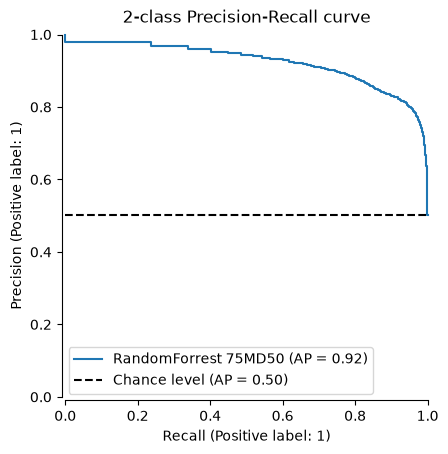

In [27]:
display = PrecisionRecallDisplay.from_estimator(rfc, valid_set.drop("present", axis=1), valid_set["present"], name="RandomForrest 75MD50", plot_chance_level=True, despine=True)
_ = display.ax_.set_title("2-class Precision-Recall curve")
display.ax_.figure.set_figwidth(20)

---
Train prepros

In [30]:
test = np.load('species/species_test.npz', allow_pickle=True)

# Features- normalise lat/lon to [-1,1], then sin/cos (SINR paper approach)
def encode(latlon):
    lat = latlon[:,0]/90
    lon = latlon[:,1]/180
    return np.column_stack([np.sin(np.pi*lon), np.cos(np.pi*lon), np.sin(np.pi*lat), np.cos(np.pi*lat)])

res = 4
grid_cells = [c for r0 in h3.get_res0_cells() for c in h3.cell_to_children(r0, res)]
cell_index = {c: i for i, c in enumerate(grid_cells)}
cell_test= []
for lat, lon in test['test_locs'].astype(float):
    cell_test.append(cell_index[h3.latlng_to_cell(lat, lon, res)])
cell_test = np.array(cell_test)

X_test = encode(test['test_locs'])
y_test = np.zeros((len(X_test), len(test['taxon_ids'])), dtype=bool)
for i, pos in enumerate(test['test_pos_inds']):
    y_test[pos, i] = 1  # species i present at these locations, 0 elsewhere

print('X_test-', X_test.shape, ', y_test-', y_test.shape, ', cell_test-', cell_test.shape)

# Save
np.savez('species/preprocessed_cells_test.npz', X_test=X_test, y_test=y_test, cell_test=cell_test, test_locs=test['test_locs'], taxon_ids=test['taxon_ids'])

# Usage for models
preprocessed = np.load('species/preprocessed_cells_test.npz')
cols = ['sin_lon', 'cos_lon', 'sin_lat', 'cos_lat']
test_df = pd.DataFrame(preprocessed['X_test'], columns=cols)
test_df['cell'] = preprocessed['cell_test']
test_df['n_species'] = preprocessed['y_test'].sum(axis=1)  # number of species present at each point
test_df['species'] = [np.flatnonzero(row) for row in preprocessed['y_test']]

X = preprocessed['X_test']
y = preprocessed['y_test'].astype(np.float32)  # for NN, 0/1 for each test point for all 500 species

print(test_df.head())

X_test- (288122, 4) , y_test- (288122, 500) , cell_test- (288122,)
    sin_lon   cos_lon   sin_lat   cos_lat    cell  n_species          species
0 -0.112586 -0.993642  0.329871  0.944026  134017          3  [162, 252, 384]
1 -0.299965 -0.953950  0.133619  0.991033  133019          3  [162, 252, 384]
2 -0.208854 -0.977947  0.149162  0.988813  132538          3  [162, 252, 384]
3 -0.178451 -0.983949  0.135019  0.990843  132482          3  [162, 252, 384]
4 -0.181306 -0.983427 -0.216004  0.976393  133649          3  [162, 252, 384]


In [48]:
# Load the climate grid
env_grid = np.load('bioclim_h3_res4.npz')['env_grid']

# Load the preprocessed test cells
preprocessed_test = np.load('species/preprocessed_cells_test.npz')
X_test = preprocessed_test['X_test']
y_test = preprocessed_test['y_test']
cell_test = preprocessed_test['cell_test']

cols = ['sin_lon',
        'cos_lon',
        'sin_lat',
        'cos_lat'
       ]

# Column names
env_cols = ['Annual Mean Temperature',
            'Temperature Seasonality',
            'Max Temperature of Warmest Month',
            'Min Temperature of Coldest Month',
            'Annual Precipitation',
            'Precipitation Seasonality',
            'Precipitation of Driest Quarter',
            'Elevation']

# Make the test df from the preprocessed test cells
test_df_bio = pd.DataFrame(X_test, columns=cols)
test_df_bio['cell'] = cell_test

# climate for each cell
test_df_bio[env_cols] = env_grid[test_df_bio['cell'].values]

# Drop cells with no climate data (ocean)
clean_test = test_df_bio[env_cols].notna().all(axis=1).values
test_df_bio = test_df_bio[clean_test]

X_test_bio = test_df_bio[cols].values
y_test_bio = y_test[clean_test]
cell_test_bio = cell_test[clean_test]

# Save
np.savez('preprocessed_test_bio.npz', X_test=X_test_bio, y_test=y_test_bio, cell_test=cell_test_bio)
print('X_test_bio-', X_test_bio.shape, ', y_test_bio-', y_test_bio.shape)

X_test_bio- (89377, 4) , y_test_bio- (89377, 500)


In [53]:
X_test_bio

array([[-0.961459  ,  0.27494842, -0.99374264, -0.11169424],
       [-0.95722103,  0.28935763, -0.99999905, -0.00136737],
       [-0.916076  ,  0.40100473, -0.98689234,  0.16138001],
       ...,
       [ 0.8835843 , -0.46827206, -0.76157427,  0.64807767],
       [ 0.90380645, -0.42794147, -0.7011241 ,  0.7130393 ],
       [ 0.91372526, -0.4063326 , -0.779461  ,  0.6264507 ]],
      shape=(89377, 4), dtype=float32)

In [36]:
test_df.explode("species").drop("n_species", axis=1)
y_test = rfc.predict(test_df.explode("species").drop("n_species", axis=1))

,sin_lon,cos_lon,sin_lat,cos_lat,cell,species
0,-0.112586,-0.993642,0.329871,0.944026,134017,162
0,-0.112586,-0.993642,0.329871,0.944026,134017,252
0,-0.112586,-0.993642,0.329871,0.944026,134017,384
1,-0.299965,-0.953950,0.133619,0.991033,133019,162
1,-0.299965,-0.953950,0.133619,0.991033,133019,252
...,...,...,...,...,...,...
288119,0.930085,-0.367343,-0.679200,0.733953,196200,384
288120,0.944465,-0.328613,-0.694563,0.719432,196908,252
288120,0.944465,-0.328613,-0.694563,0.719432,196908,384
288121,0.961415,-0.275103,-0.734893,0.678183,197468,252


In [ ]:
pred_test = rfc.predict(test_df.explode("species").drop(["n_species", "cell"], axis=1))
y_test = np.full((len(pred_test),1), 1)
matrix = confusion_matrix(y_test, pred_test)
matrix = matrix.astype('float') / matrix.sum(axis=1)[:, np.newaxis]
sns.heatmap(matrix, annot=True, fmt=".2f")
plt.xticks(rotation=25)
plt.yticks(rotation=0)
plt.xlabel("Predicted labels")
plt.ylabel("True labels")
plt.show()